In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("FinGuard environment is ready!")


Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python executable: c:\Users\Sarthak\OneDrive\Desktop\FINTECH\venv\Scripts\python.exe
FinGuard environment is ready!


In [2]:
import pandas as pd
import os

data_folder = "../data"

csv_files = [
    f for f in os.listdir(data_folder)
    if f.endswith(".csv")
]

print(csv_files)

[]


In [4]:
import pandas as pd
from pathlib import Path

data_folder = Path("data")

csv_files = list(data_folder.glob("*.csv"))

print("CSV files found:", csv_files)

if not csv_files:
    print("No CSV found! Check your data folder.")
else:
    df = pd.read_csv(csv_files[0])

    print("Dataset loaded successfully!")
    print("Shape:", df.shape)

    display(df.head())

CSV files found: []
No CSV found! Check your data folder.


In [6]:
from pathlib import Path

cwd = Path.cwd()

print("Current working directory:", cwd)

# Find the project root
project_root = next(
    (
        p for p in [cwd, *cwd.parents]
        if (p / ".gitignore").exists()
        and (p / "data").is_dir()
    ),
    None
)

if project_root:
    print("Project root:", project_root)

    csv_files = list((project_root / "data").rglob("*.csv"))

    print("\nCSV files found:")
    for file in csv_files:
        print(file)
else:
    print("Project root not found.")

Current working directory: c:\Users\Sarthak\OneDrive\Desktop\FINTECH\notebooks
Project root: c:\Users\Sarthak\OneDrive\Desktop\FINTECH

CSV files found:
c:\Users\Sarthak\OneDrive\Desktop\FINTECH\data\indian_banking_transactions.csv


In [7]:
import pandas as pd
import numpy as np
from pathlib import Path

# Locate the project directory
project_root = Path.cwd()

while not (project_root / "data").is_dir():
    project_root = project_root.parent

# Locate the CSV file
csv_files = list((project_root / "data").glob("*.csv"))

# Load the dataset
file_path = csv_files[0]
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (550000, 20)


In [8]:
df.head()

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764,0,NaN,0.00,Success,Branch,Verified,0,15
1,TXN000000002,CUST000861,2019-01-01,03:00,Current,UPI,392.67,Credit,14451.14,Education,West Bengal,630,0,NaN,0.00,Success,Mobile_App,Verified,0,3
2,TXN000000003,CUST076821,2019-01-01,18:03,Fixed Deposit,POS,1255.97,Debit,47621.87,Utilities,Punjab,813,1,Home,1433.91,Success,Mobile_App,Verified,0,18
3,TXN000000004,CUST054887,2019-01-01,08:03,Savings,UPI,2580.68,Debit,34467.85,Travel,Karnataka,628,1,Personal,6280.35,Success,API,Verified,0,8
4,TXN000000005,CUST006266,2019-01-01,14:23,Fixed Deposit,UPI,2573.80,Debit,26617.40,Utilities,West Bengal,767,0,NaN,0.00,Success,API,Verified,0,14


In [9]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())


Total rows: 550000
Total columns: 20

Column names:
['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'account_type', 'transaction_type', 'transaction_amount', 'transaction_direction', 'account_balance', 'merchant_category', 'state', 'credit_score', 'has_loan', 'loan_type', 'emi_amount', 'transaction_status', 'channel', 'kyc_status', 'is_fraud', 'transaction_hour']


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 550000 entries, 0 to 549999
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   transaction_id         550000 non-null  str    
 1   customer_id            550000 non-null  str    
 2   transaction_date       550000 non-null  str    
 3   transaction_time       550000 non-null  str    
 4   account_type           550000 non-null  str    
 5   transaction_type       550000 non-null  str    
 6   transaction_amount     550000 non-null  float64
 7   transaction_direction  550000 non-null  str    
 8   account_balance        550000 non-null  float64
 9   merchant_category      550000 non-null  str    
 10  state                  550000 non-null  str    
 11  credit_score           550000 non-null  int64  
 12  has_loan               550000 non-null  int64  
 13  loan_type              172866 non-null  str    
 14  emi_amount             550000 non-null  float64

In [11]:
df.isnull().sum()


transaction_id                0
customer_id                   0
transaction_date              0
transaction_time              0
account_type                  0
transaction_type              0
transaction_amount            0
transaction_direction         0
account_balance               0
merchant_category             0
state                         0
credit_score                  0
has_loan                      0
loan_type                377134
emi_amount                    0
transaction_status            0
channel                       0
kyc_status                    0
is_fraud                      0
transaction_hour              0
dtype: int64

In [12]:
df.shape

(550000, 20)

In [13]:
# Check relationship between has_loan and loan_type

loan_check = pd.crosstab(
    df["has_loan"],
    df["loan_type"].isna(),
    margins=True
)

loan_check

loan_type,False,True,All
has_loan,,,
0,0,357712,357712
1,172866,19422,192288
All,172866,377134,550000


In [14]:
print("Loan status distribution:")
print(df["has_loan"].value_counts(dropna=False))

print("\nLoan type distribution:")
print(df["loan_type"].value_counts(dropna=False))

Loan status distribution:
has_loan
0    357712
1    192288
Name: count, dtype: int64

Loan type distribution:
loan_type
NaN          377134
Personal      47810
Home          38252
Auto          29219
Business      28863
Education     19074
Gold           9648
Name: count, dtype: int64


In [15]:
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate transaction IDs:",
    df["transaction_id"].duplicated().sum()
)

Duplicate rows: 0
Duplicate transaction IDs: 0


In [17]:
# Preserve the original dataset
df_clean = df.copy()

print("Original dataset:", df.shape)
print("Working dataset:", df_clean.shape)

Original dataset: (550000, 20)
Working dataset: (550000, 20)


DATA CLEANING


In [18]:
import pandas as pd
import numpy as np
from pathlib import Path

# Preserve original data
df_clean = df.copy()

print("Original shape:", df.shape)
print("Working copy shape:", df_clean.shape)

# Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("\nColumns standardized successfully!")

Original shape: (550000, 20)
Working copy shape: (550000, 20)

Columns standardized successfully!


In [19]:
# Check loan status
print(df_clean["has_loan"].value_counts(dropna=False))

# Handle missing loan types
df_clean.loc[
    (df_clean["has_loan"] == 0) &
    (df_clean["loan_type"].isna()),
    "loan_type"
] = "Not Applicable"

df_clean.loc[
    (df_clean["has_loan"] == 1) &
    (df_clean["loan_type"].isna()),
    "loan_type"
] = "Unknown"

# Check remaining missing values
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

has_loan
0    357712
1    192288
Name: count, dtype: int64

Missing values after cleaning:
transaction_id           0
customer_id              0
transaction_date         0
transaction_time         0
account_type             0
transaction_type         0
transaction_amount       0
transaction_direction    0
account_balance          0
merchant_category        0
state                    0
credit_score             0
has_loan                 0
loan_type                0
emi_amount               0
transaction_status       0
channel                  0
kyc_status               0
is_fraud                 0
transaction_hour         0
dtype: int64


In [20]:
# Count exact duplicate rows
duplicate_rows = df_clean.duplicated().sum()

print("Duplicate rows found:", duplicate_rows)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

print("Shape after removing exact duplicates:", df_clean.shape)

# Check duplicate transaction IDs separately
duplicate_ids = df_clean["transaction_id"].duplicated().sum()

print("Duplicate transaction IDs:", duplicate_ids)

Duplicate rows found: 0
Shape after removing exact duplicates: (550000, 20)
Duplicate transaction IDs: 0


In [21]:
# Convert date column
df_clean["transaction_date"] = pd.to_datetime(
    df_clean["transaction_date"],
    errors="coerce"
)

# Convert time column
df_clean["transaction_time"] = pd.to_datetime(
    df_clean["transaction_time"],
    format="%H:%M:%S",
    errors="coerce"
).dt.time

# Clean categorical text
categorical_columns = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for col in categorical_columns:
    df_clean[col] = df_clean[col].str.strip()

# Check invalid numerical values
print("Negative transaction amounts:",
      (df_clean["transaction_amount"] < 0).sum())

print("Negative account balances:",
      (df_clean["account_balance"] < 0).sum())

print("Invalid fraud labels:",
      (~df_clean["is_fraud"].isin([0, 1])).sum())

print("Invalid loan flags:",
      (~df_clean["has_loan"].isin([0, 1])).sum())

Negative transaction amounts: 0
Negative account balances: 0
Invalid fraud labels: 0
Invalid loan flags: 0


In [22]:
# Final cleaning report
print("========== CLEANING REPORT ==========")

print("Final dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

print("\nFraud distribution:")
print(df_clean["is_fraud"].value_counts())

print("\nData types:")
print(df_clean.dtypes)

# Save cleaned dataset
output_path = Path("../data/cleaned_banking_transactions.csv")

output_path.parent.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(output_path, index=False)

print("\nCleaned dataset saved at:", output_path.resolve())

========== CLEANING REPORT ==========
Final dataset shape: (550000, 20)

Missing values:
transaction_id                0
customer_id                   0
transaction_date              0
transaction_time         550000
account_type                  0
transaction_type              0
transaction_amount            0
transaction_direction         0
account_balance               0
merchant_category             0
state                         0
credit_score                  0
has_loan                      0
loan_type                     0
emi_amount                    0
transaction_status            0
channel                       0
kyc_status                    0
is_fraud                      0
transaction_hour              0
dtype: int64

Duplicate rows: 0

Fraud distribution:
is_fraud
0    545127
1      4873
Name: count, dtype: int64

Data types:
transaction_id                      str
customer_id                         str
transaction_date         datetime64[us]
transaction_time          

#EXploratry Data Analysis(EDA)


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Load cleaned dataset
print("Dataset shape:", df_clean.shape)

print("\nFraud distribution:")
print(df_clean["is_fraud"].value_counts())

Dataset shape: (550000, 20)

Fraud distribution:
is_fraud
0    545127
1      4873
Name: count, dtype: int64


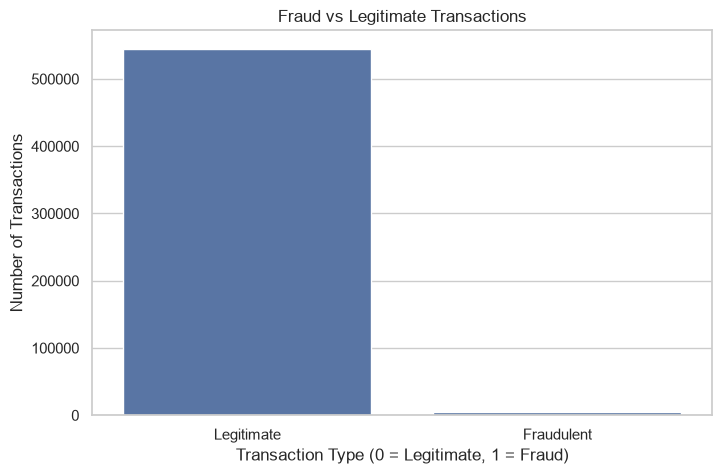

Fraud percentages:
is_fraud
0    99.11
1     0.89
Name: proportion, dtype: float64


In [24]:
# Count legitimate and fraudulent transactions
fraud_counts = df_clean["is_fraud"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=fraud_counts.index,
    y=fraud_counts.values
)

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Type (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])

plt.show()

# Calculate percentages
print("Fraud percentages:")
print(
    (df_clean["is_fraud"].value_counts(normalize=True) * 100)
    .round(2)
)

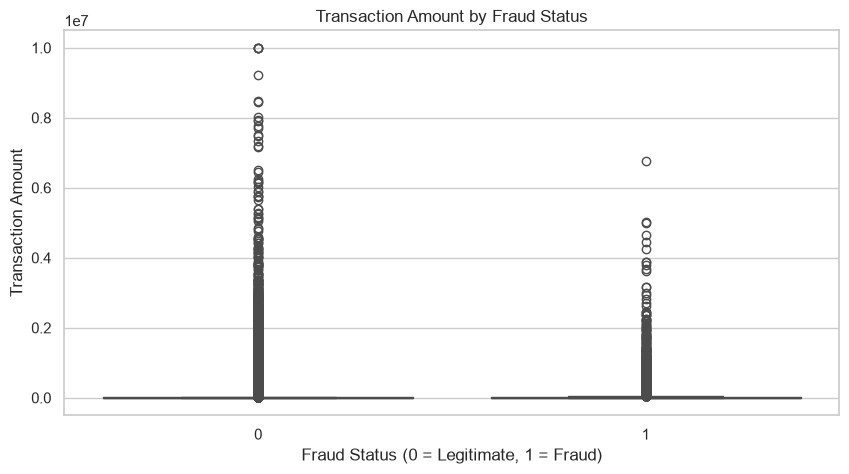

In [25]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x="is_fraud",
    y="transaction_amount"
)

plt.title("Transaction Amount by Fraud Status")
plt.xlabel("Fraud Status (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")

plt.show()

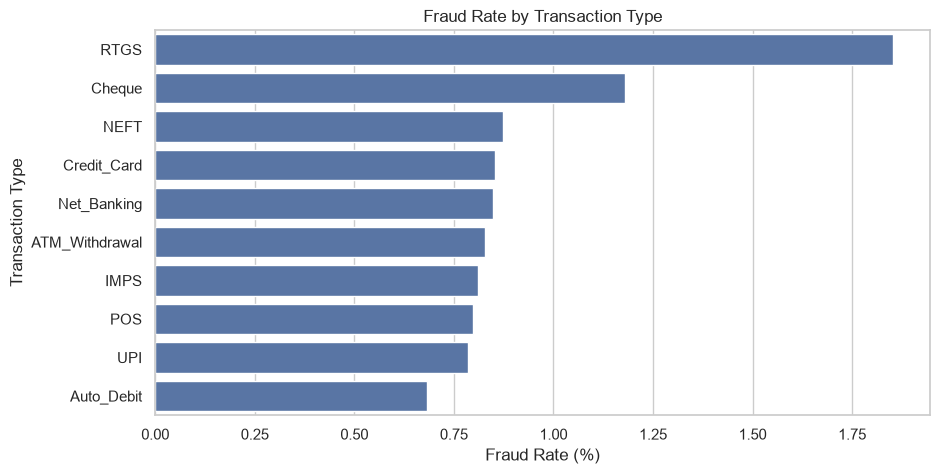

transaction_type
RTGS              1.85
Cheque            1.18
NEFT              0.87
Credit_Card       0.85
Net_Banking       0.85
ATM_Withdrawal    0.83
IMPS              0.81
POS               0.80
UPI               0.79
Auto_Debit        0.68
Name: is_fraud, dtype: float64


In [26]:
fraud_by_type = (
    df_clean.groupby("transaction_type")["is_fraud"]
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=fraud_by_type.values,
    y=fraud_by_type.index
)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Transaction Type")

plt.show()

print(fraud_by_type.round(2))

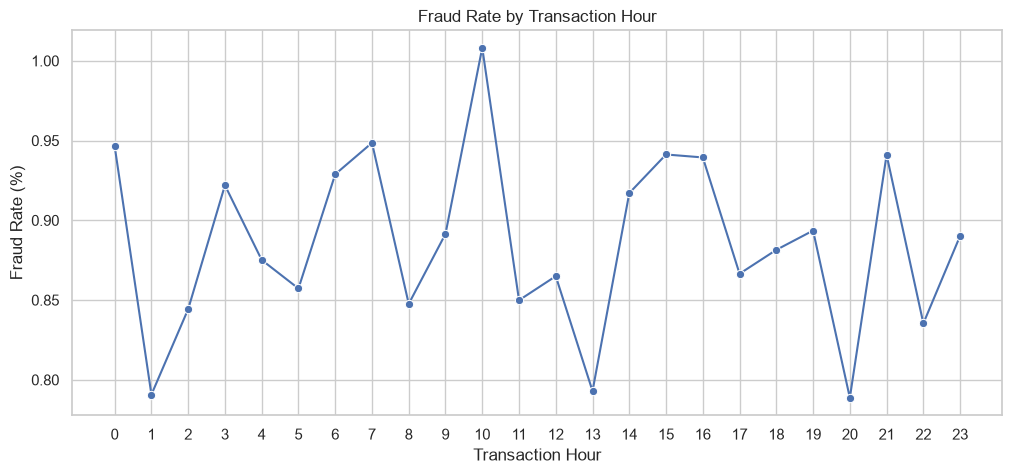

In [27]:
fraud_by_hour = (
    df_clean.groupby("transaction_hour")["is_fraud"]
    .mean() * 100
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=fraud_by_hour.index,
    y=fraud_by_hour.values,
    marker="o"
)

plt.title("Fraud Rate by Transaction Hour")
plt.xlabel("Transaction Hour")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(0, 24))

plt.show()

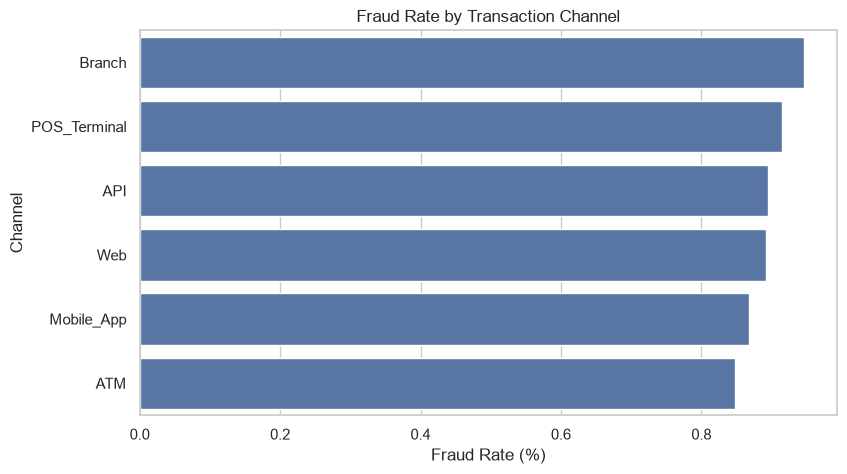

channel
Branch          0.95
POS_Terminal    0.92
API             0.90
Web             0.89
Mobile_App      0.87
ATM             0.85
Name: is_fraud, dtype: float64


In [28]:
fraud_by_channel = (
    df_clean.groupby("channel")["is_fraud"]
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=fraud_by_channel.values,
    y=fraud_by_channel.index
)

plt.title("Fraud Rate by Transaction Channel")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Channel")

plt.show()

print(fraud_by_channel.round(2))

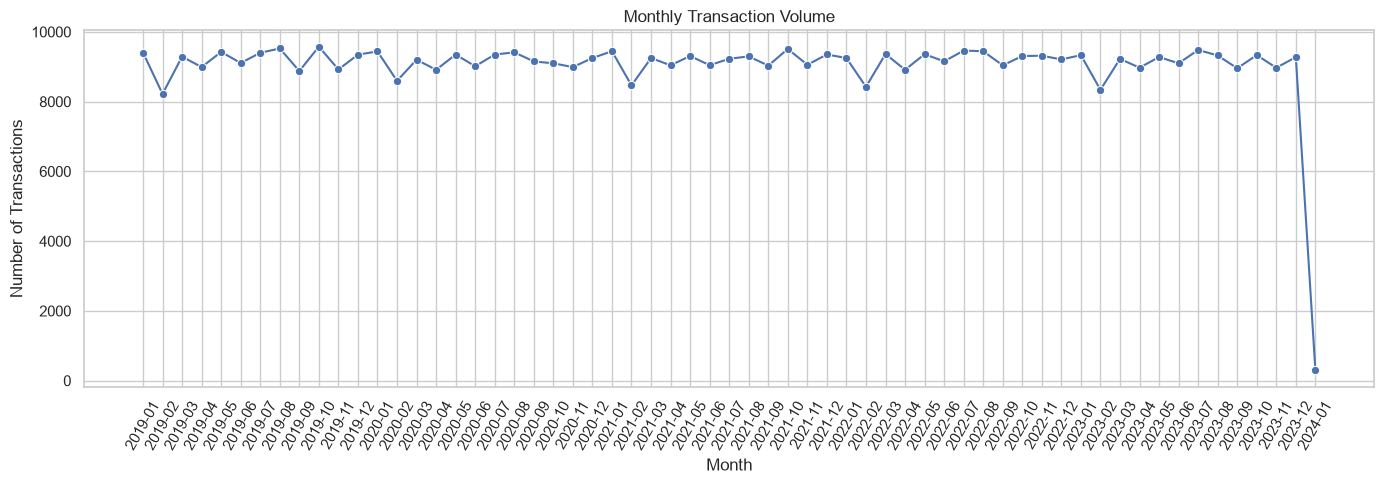

In [30]:
df_clean["transaction_month"] = (
    df_clean["transaction_date"].dt.to_period("M").astype(str)
)

monthly_transactions = (
    df_clean.groupby("transaction_month")
    .size()
)

plt.figure(figsize=(14, 5))

sns.lineplot(
    x=monthly_transactions.index,
    y=monthly_transactions.values,
    marker="o"
)

plt.title("Monthly Transaction Volume")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=60)

plt.tight_layout()
plt.show()

#FEATURE ENGINEERING

In [31]:
# Preserve our cleaned dataset
df_ml = df_clean.copy()

print("Dataset shape:", df_ml.shape)
print("Available columns:")
print(df_ml.columns.tolist())

Dataset shape: (550000, 21)
Available columns:
['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'account_type', 'transaction_type', 'transaction_amount', 'transaction_direction', 'account_balance', 'merchant_category', 'state', 'credit_score', 'has_loan', 'loan_type', 'emi_amount', 'transaction_status', 'channel', 'kyc_status', 'is_fraud', 'transaction_hour', 'transaction_month']


In [32]:
# Ensure date column is datetime
df_ml["transaction_date"] = pd.to_datetime(
    df_ml["transaction_date"],
    errors="coerce"
)

# Extract date information
df_ml["transaction_year"] = df_ml["transaction_date"].dt.year

df_ml["transaction_month"] = df_ml["transaction_date"].dt.month

df_ml["transaction_day"] = df_ml["transaction_date"].dt.day

df_ml["transaction_dayofweek"] = (
    df_ml["transaction_date"].dt.dayofweek
)

# Monday-Friday = 0, Saturday-Sunday = 1
df_ml["is_weekend"] = (
    df_ml["transaction_dayofweek"] >= 5
).astype(int)

print("Date features created successfully!")

Date features created successfully!


C:\Users\Sarthak\AppData\Local\Temp\ipykernel_28080\72946724.py:15: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_ml["transaction_date"].dt.dayofweek


In [33]:
# Convert transaction hour into numeric format
df_ml["transaction_hour"] = pd.to_numeric(
    df_ml["transaction_hour"],
    errors="coerce"
)

# Night transactions: 10 PM to 6 AM
df_ml["is_night"] = (
    (df_ml["transaction_hour"] >= 22) |
    (df_ml["transaction_hour"] < 6)
).astype(int)

print("Night transactions created!")
print(df_ml[["transaction_hour", "is_night"]].head())

Night transactions created!
   transaction_hour  is_night
0                15         0
1                 3         1
2                18         0
3                 8         0
4                14         0


In [34]:
# Log transformation of transaction amount
df_ml["amount_log"] = np.log1p(
    df_ml["transaction_amount"].clip(lower=0)
)

# Transaction amount relative to account balance
df_ml["amount_balance_ratio"] = (
    df_ml["transaction_amount"] /
    (df_ml["account_balance"].abs() + 1)
)

print("Amount-based features created!")

Amount-based features created!


In [35]:
# Recreate the suspected synthetic rule
df_ml["suspected_rule"] = (
    (df_ml["transaction_hour"] >= 22) |
    (df_ml["transaction_hour"] < 6)
) & (
    df_ml["transaction_amount"] > 500000
)

# Compare suspected rule with actual fraud labels
print(pd.crosstab(
    df_ml["suspected_rule"],
    df_ml["is_fraud"],
    normalize="index"
).round(4))

# Calculate fraud rate for matching transactions
print("\nFraud rate when suspected rule matches:")
print(
    df_ml.groupby("suspected_rule")["is_fraud"]
    .mean()
    .mul(100)
    .round(2)
)

is_fraud             0       1
suspected_rule                
False           0.9914  0.0086
True            0.9226  0.0774

Fraud rate when suspected rule matches:
suspected_rule
False    0.86
True     7.74
Name: is_fraud, dtype: float64


In [36]:
new_features = [
    "transaction_year",
    "transaction_month",
    "transaction_dayofweek",
    "is_weekend",
    "is_night",
    "amount_log",
    "amount_balance_ratio"
]

print(df_ml[new_features].head())

print("\nNew dataset shape:", df_ml.shape)

   transaction_year  transaction_month  transaction_dayofweek  is_weekend  \
0              2019                  1                      1           0   
1              2019                  1                      1           0   
2              2019                  1                      1           0   
3              2019                  1                      1           0   
4              2019                  1                      1           0   

   is_night  amount_log  amount_balance_ratio  
0         0    7.507234              0.002987  
1         1    5.975513              0.027170  
2         0    7.136459              0.026373  
3         0    7.856196              0.074870  
4         0    7.853527              0.096693  

New dataset shape: (550000, 29)


In [38]:
output_path = Path("../data/engineered_banking_transactions.csv")

df_ml.to_csv(output_path, index=False)

print("Feature engineering completed!")
print("Saved at:", output_path.resolve())

Feature engineering completed!
Saved at: C:\Users\Sarthak\OneDrive\Desktop\FINTECH\data\engineered_banking_transactions.csv


In [ ]:
#machine learning component on finfgaurx


In [39]:
# Import required libraries
import pandas as pd
import numpy as np

# Create modelling dataset
model_df = df_ml.copy()

# Define target variable
target = "is_fraud"

# Separate features and target
y = model_df[target].astype(int)

# Remove columns that should not be used as predictors
columns_to_drop = [
    target,
    "transaction_id",
    "customer_id",
    "account_id",
    "transaction_date",
    "transaction_time",
    "transaction_hour",
    "transaction_amount",
    "amount_log",
    "amount_balance_ratio",
    "is_night",
    "suspected_rule"
]

X = model_df.drop(
    columns=columns_to_drop,
    errors="ignore"
)

# Remove columns that are entirely empty
X = X.dropna(axis=1, how="all")

# Remove constant columns
X = X.loc[:, X.nunique(dropna=False) > 1]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (550000, 18)
Target shape: (550000,)

Target distribution:
is_fraud
0    545127
1      4873
Name: count, dtype: int64


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining fraud distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting fraud distribution:")
print(y_test.value_counts(normalize=True))

Training records: 440000
Testing records: 110000

Training fraud distribution:
is_fraud
0    0.991141
1    0.008859
Name: proportion, dtype: float64

Testing fraud distribution:
is_fraud
0    0.991136
1    0.008864
Name: proportion, dtype: float64


In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created!")

Numerical features: 9
Categorical features: 9
Preprocessing pipeline created!


In [42]:
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=12,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "SGD Classifier": SGDClassifier(
        loss="log_loss",
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
}

print("Five machine learning models initialized!")

Five machine learning models initialized!


In [44]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

trained_models = {}
results = []

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Create independent preprocessing and model pipeline
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(model))
    ])

    # Train
    pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Evaluation
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

    trained_models[name] = pipeline

    print(f"{name} training completed!")

print("\nAll models trained successfully!")


Training Logistic Regression...
Logistic Regression training completed!

Training Decision Tree...
Decision Tree training completed!

Training Random Forest...
Random Forest training completed!

Training Extra Trees...
Extra Trees training completed!

Training SGD Classifier...
SGD Classifier training completed!

All models trained successfully!


In [45]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.7044,0.0108,0.3559,0.0209,0.5379,0.0118
1,SGD Classifier,0.5394,0.0094,0.4862,0.0184,0.5290,0.0115
2,Random Forest,0.9911,0.0000,0.0000,0.0000,0.5327,0.0107
3,Decision Tree,0.5023,0.0089,0.5026,0.0176,0.5046,0.0099
4,Extra Trees,0.9911,0.0000,0.0000,0.0000,0.5252,0.0096


In [47]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.7044,0.0108,0.3559,0.0209,0.5379,0.0118
1,SGD Classifier,0.5394,0.0094,0.4862,0.0184,0.5290,0.0115
2,Random Forest,0.9911,0.0000,0.0000,0.0000,0.5327,0.0107
3,Decision Tree,0.5023,0.0089,0.5026,0.0176,0.5046,0.0099
4,Extra Trees,0.9911,0.0000,0.0000,0.0000,0.5252,0.0096


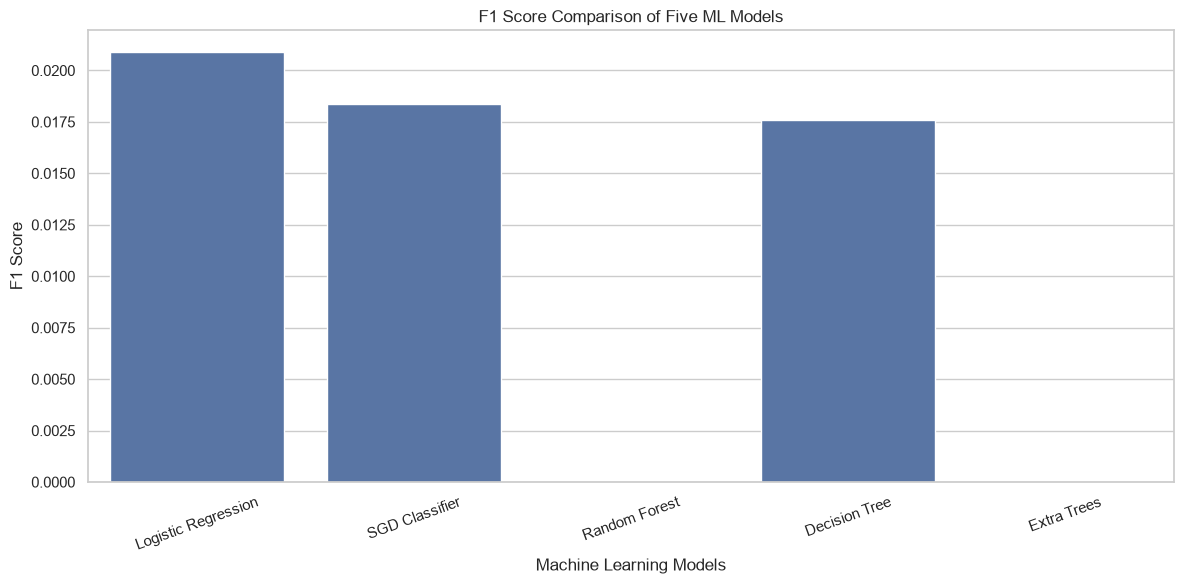

In [48]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score"
)

plt.title("F1 Score Comparison of Five ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("F1 Score")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

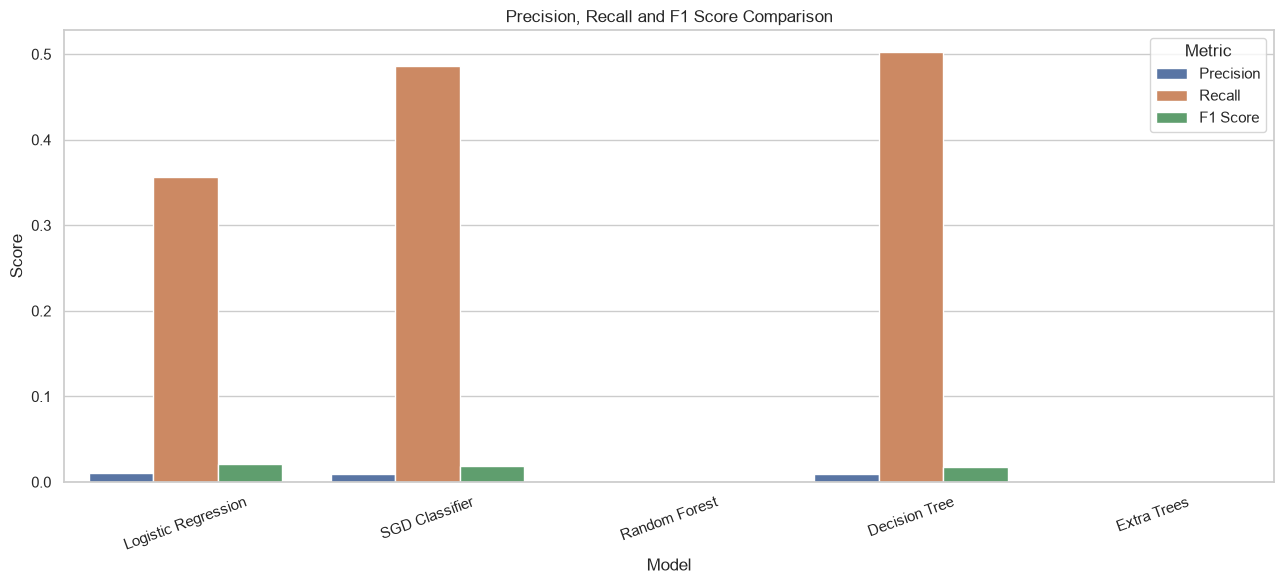

In [49]:
comparison = results_df.melt(
    id_vars="Model",
    value_vars=["Precision", "Recall", "F1 Score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=comparison,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 Score Comparison")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [50]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best model:", best_model_name)

Best model: Logistic Regression


In [51]:
from sklearn.metrics import classification_report

y_pred = best_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

              precision    recall  f1-score   support

  Legitimate       0.99      0.71      0.83    109025
       Fraud       0.01      0.36      0.02       975

    accuracy                           0.70    110000
   macro avg       0.50      0.53      0.42    110000
weighted avg       0.98      0.70      0.82    110000



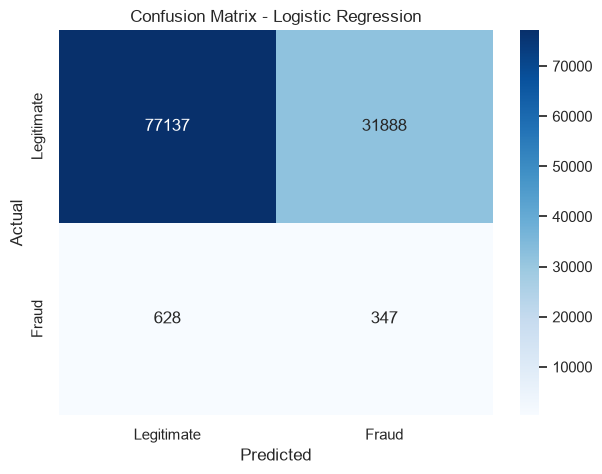

In [52]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [53]:
import joblib
from pathlib import Path

output_folder = Path("../outputs")
output_folder.mkdir(parents=True, exist_ok=True)

# Save comparison table
results_df.to_csv(
    output_folder / "model_comparison.csv",
    index=False
)

# Save trained model
joblib.dump(
    best_model,
    output_folder / "best_fraud_model.pkl"
)

print("Model comparison saved!")
print("Best model saved:", best_model_name)

Model comparison saved!
Best model saved: Logistic Regression


In [54]:
rule = (
    (
        (df_ml["transaction_hour"] >= 22) |
        (df_ml["transaction_hour"] < 6)
    )
    &
    (df_ml["transaction_amount"] > 500000)
)

print(pd.crosstab(
    rule,
    df_ml["is_fraud"],
    normalize="index"
).round(4))

is_fraud       0       1
row_0                   
False     0.9914  0.0086
True      0.9226  0.0774


Project root: c:\Users\Sarthak\OneDrive\Desktop\FINTECH

TARGET LEAKAGE AUDIT
is_fraud       0       1
row_0                   
False     0.9914  0.0086
True      0.9226  0.0774

Fraud rate by suspected rule:
False    0.86
True     7.74
Name: is_fraud, dtype: float64

Features removed:
[]

Remaining features: 18

DATA SPLIT
Training: (352000, 18)
Validation: (88000, 18)
Testing: (110000, 18)

Preprocessing pipeline ready!

Training leakage-aware model: Logistic Regression

Training leakage-aware model: Decision Tree

Training leakage-aware model: Random Forest

Training leakage-aware model: Extra Trees

Training leakage-aware model: SGD Classifier

All leakage-aware models trained!

LEAKAGE-AWARE MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.7142,0.0109,0.3474,0.0211,0.5397,0.0110
1,Decision Tree,0.6914,0.0109,0.3782,0.0213,0.5442,0.0106
2,SGD Classifier,0.3244,0.0090,0.6910,0.0178,0.5261,0.0104
3,Random Forest,0.9911,0.0000,0.0000,0.0000,0.5218,0.0096
4,Extra Trees,0.9911,0.0000,0.0000,0.0000,0.4960,0.0091


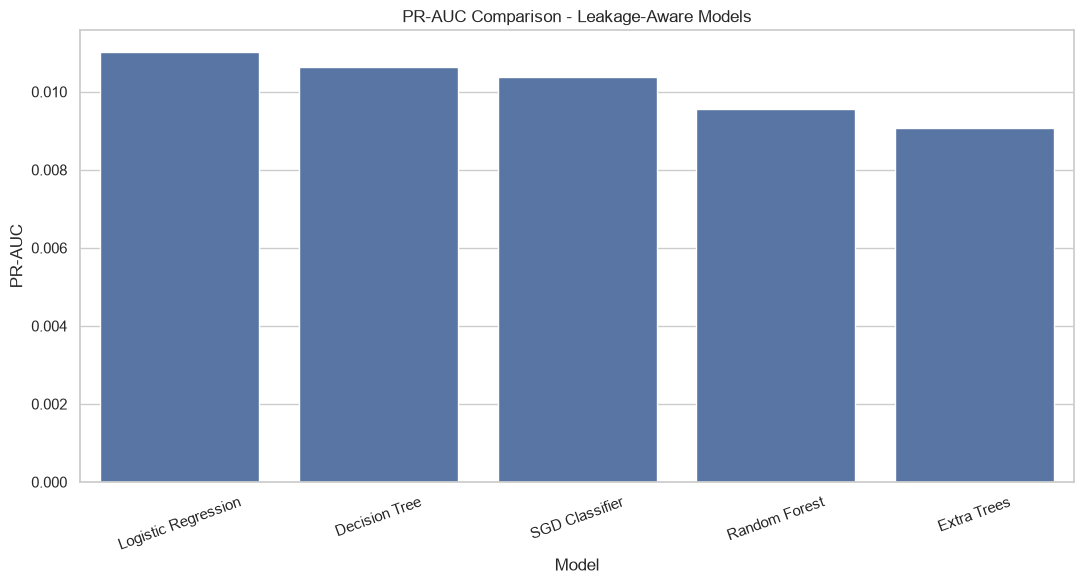


Selected model: Logistic Regression

Optimized threshold: 0.569
Validation F1: 0.0284


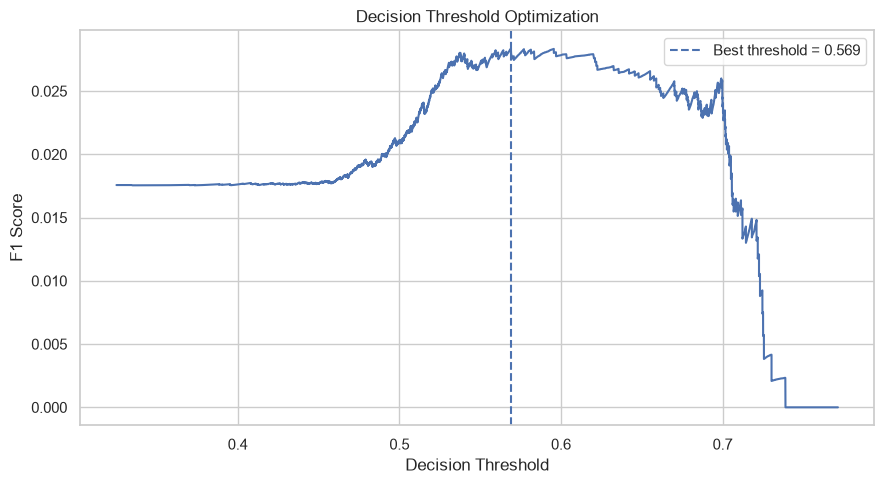


FINAL TEST RESULTS
              precision    recall  f1-score   support

  Legitimate       0.99      0.93      0.96    109025
       Fraud       0.02      0.13      0.03       975

    accuracy                           0.92    110000
   macro avg       0.50      0.53      0.50    110000
weighted avg       0.98      0.92      0.95    110000


FINAL METRICS


,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.569,0.9246,0.0166,0.1292,0.0295,0.5402,0.0117


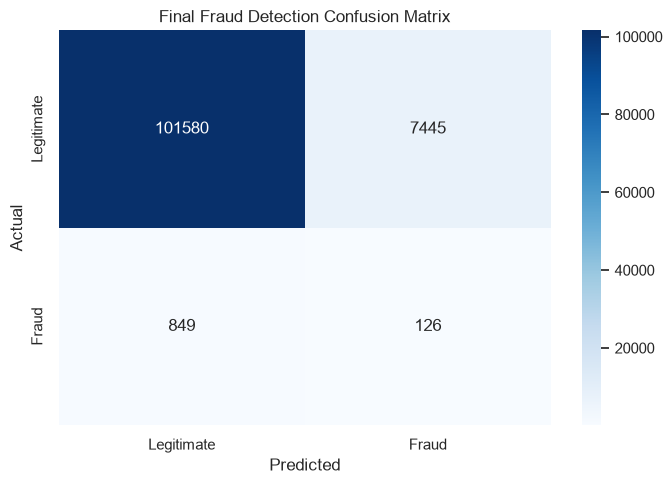

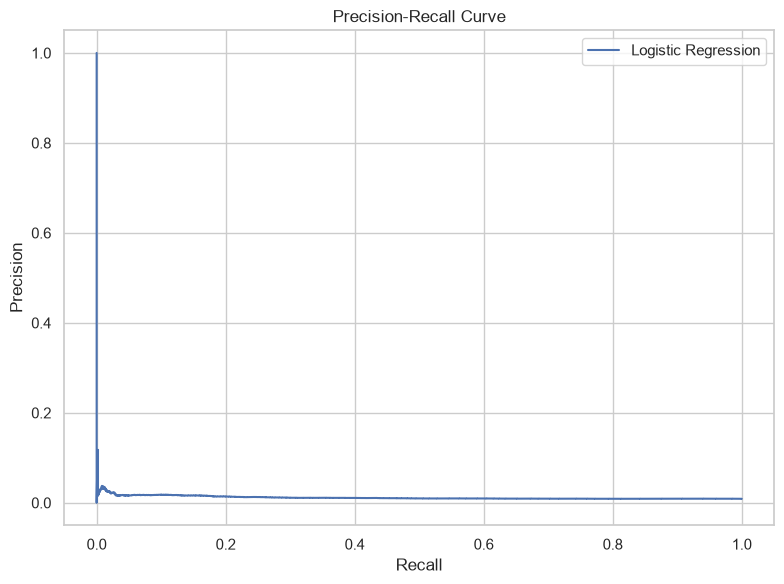

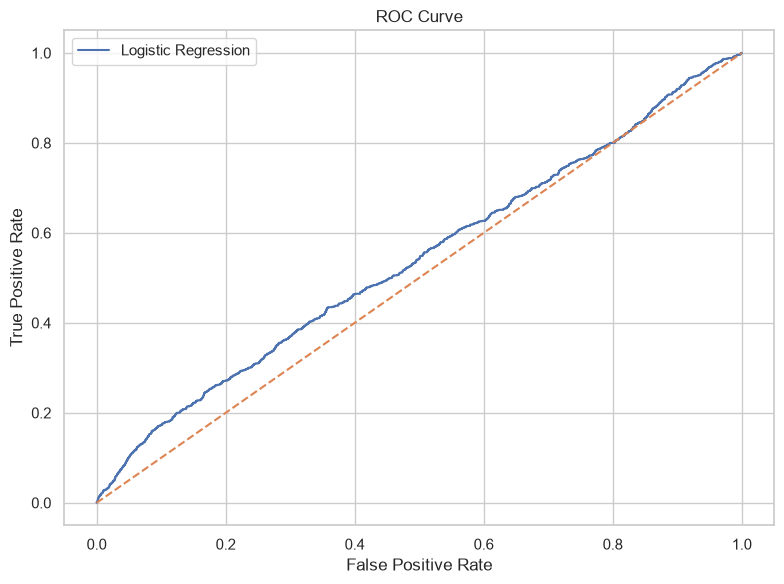

Selected model does not provide native tree-based feature importance.

FINGUARD ML EXPERIMENT COMPLETED
Selected model: Logistic Regression
Final threshold: 0.569
Test PR-AUC: 0.0117
Test F1 Score: 0.0295

Results saved in: c:\Users\Sarthak\OneDrive\Desktop\FINTECH\outputs
Visualizations saved in: c:\Users\Sarthak\OneDrive\Desktop\FINTECH\visualizations


In [55]:

# ============================================================
# FINGUARD - FINAL MACHINE LEARNING EXPERIMENTS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)

# Find project root automatically
current = Path.cwd()

while current != current.parent:
    if (current / "data").is_dir():
        PROJECT_ROOT = current
        break
    current = current.parent
else:
    raise FileNotFoundError("FINTECH project folder not found")

OUTPUT_DIR = PROJECT_ROOT / "outputs"
VIZ_DIR = PROJECT_ROOT / "visualizations"

OUTPUT_DIR.mkdir(exist_ok=True)
VIZ_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

print("Project root:", PROJECT_ROOT)


# ============================================================
# 1. TARGET LEAKAGE INVESTIGATION
# ============================================================

audit_data = df_ml.copy()

suspected_rule = (
    (
        (audit_data["transaction_hour"] >= 22) |
        (audit_data["transaction_hour"] < 6)
    )
    &
    (audit_data["transaction_amount"] > 500000)
)

print("\nTARGET LEAKAGE AUDIT")

print(
    pd.crosstab(
        suspected_rule,
        audit_data["is_fraud"],
        normalize="index"
    ).round(4)
)

print("\nFraud rate by suspected rule:")

print(
    audit_data.groupby(suspected_rule)["is_fraud"]
    .mean()
    .mul(100)
    .round(2)
)


# ============================================================
# 2. CREATE LEAKAGE-AWARE FEATURE SET
# ============================================================

# Remove features directly involved in the suspected rule
# and features derived from them.

suspicious_features = [
    "transaction_hour",
    "transaction_amount",
    "is_night",
    "amount_log",
    "amount_balance_ratio"
]

X_safe = X.drop(
    columns=suspicious_features,
    errors="ignore"
).copy()

print("\nFeatures removed:")
print([c for c in suspicious_features if c in X.columns])

print("\nRemaining features:", X_safe.shape[1])


# ============================================================
# 3. CREATE TRAINING, VALIDATION AND TEST SETS
# ============================================================

X_train_full, X_test_safe, y_train_full, y_test_safe = (
    train_test_split(
        X_safe,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

X_train_safe, X_val_safe, y_train_safe, y_val_safe = (
    train_test_split(
        X_train_full,
        y_train_full,
        test_size=0.20,
        random_state=42,
        stratify=y_train_full
    )
)

print("\nDATA SPLIT")

print("Training:", X_train_safe.shape)
print("Validation:", X_val_safe.shape)
print("Testing:", X_test_safe.shape)


# ============================================================
# 4. BUILD PREPROCESSING PIPELINE FOR SAFE FEATURES
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_features_safe = X_train_safe.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features_safe = X_train_safe.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

numeric_pipeline_safe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_safe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_safe = ColumnTransformer([
    ("num", numeric_pipeline_safe, numeric_features_safe),
    ("cat", categorical_pipeline_safe, categorical_features_safe)
])

print("\nPreprocessing pipeline ready!")


# ============================================================
# 5. TRAIN ALL FIVE MODELS WITHOUT SUSPICIOUS FEATURES
# ============================================================

safe_models = {}

for name, model in models.items():

    print("\nTraining leakage-aware model:", name)

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor_safe)),
        ("classifier", clone(model))
    ])

    pipeline.fit(X_train_safe, y_train_safe)

    safe_models[name] = pipeline

print("\nAll leakage-aware models trained!")


# ============================================================
# 6. COMPARE LEAKAGE-AWARE MODELS
# ============================================================

safe_results = []

for name, pipeline in safe_models.items():

    predictions = pipeline.predict(X_val_safe)
    probabilities = pipeline.predict_proba(X_val_safe)[:, 1]

    safe_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val_safe, predictions),
        "Precision": precision_score(
            y_val_safe, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_safe, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val_safe, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_val_safe, probabilities
        ),
        "PR-AUC": average_precision_score(
            y_val_safe, probabilities
        )
    })

safe_results_df = pd.DataFrame(safe_results)

safe_results_df = safe_results_df.sort_values(
    "PR-AUC",
    ascending=False
).reset_index(drop=True)

print("\nLEAKAGE-AWARE MODEL COMPARISON")

display(safe_results_df.round(4))


# ============================================================
# 7. VISUALIZE MODEL PERFORMANCE
# ============================================================

plt.figure(figsize=(11, 6))

sns.barplot(
    data=safe_results_df,
    x="Model",
    y="PR-AUC"
)

plt.title("PR-AUC Comparison - Leakage-Aware Models")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    VIZ_DIR / "safe_model_comparison.png",
    dpi=300
)

plt.show()


# ============================================================
# 8. SELECT MODEL USING VALIDATION PR-AUC
# ============================================================

best_safe_name = safe_results_df.iloc[0]["Model"]

best_safe_model = safe_models[best_safe_name]

print("\nSelected model:", best_safe_name)


# ============================================================
# 9. DECISION THRESHOLD OPTIMIZATION
# ============================================================

# Use validation predictions to choose a threshold.
# Do not use the test set for threshold selection.

validation_probabilities = (
    best_safe_model.predict_proba(X_val_safe)[:, 1]
)

precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_val_safe,
        validation_probabilities
    )
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    /
    (
        precision_values[:-1] +
        recall_values[:-1] + 1e-10
    )
)

best_threshold_index = np.argmax(f1_values)

best_threshold = thresholds[best_threshold_index]

print("\nOptimized threshold:", round(best_threshold, 4))
print("Validation F1:", round(f1_values[best_threshold_index], 4))

plt.figure(figsize=(9, 5))

plt.plot(thresholds, f1_values)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best threshold = {best_threshold:.3f}"
)

plt.title("Decision Threshold Optimization")
plt.xlabel("Decision Threshold")
plt.ylabel("F1 Score")
plt.legend()
plt.tight_layout()

plt.savefig(
    VIZ_DIR / "threshold_optimization.png",
    dpi=300
)

plt.show()


# ============================================================
# 10. FINAL EVALUATION ON UNSEEN TEST DATA
# ============================================================

test_probabilities = (
    best_safe_model.predict_proba(X_test_safe)[:, 1]
)

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("\nFINAL TEST RESULTS")

print(
    classification_report(
        y_test_safe,
        test_predictions,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

final_metrics = {
    "Model": best_safe_name,
    "Threshold": float(best_threshold),
    "Accuracy": accuracy_score(y_test_safe, test_predictions),
    "Precision": precision_score(
        y_test_safe, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test_safe, test_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test_safe, test_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test_safe, test_probabilities
    ),
    "PR-AUC": average_precision_score(
        y_test_safe, test_probabilities
    )
}

print("\nFINAL METRICS")

display(pd.DataFrame([final_metrics]).round(4))


# ============================================================
# 11. FINAL CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test_safe,
    test_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Final Fraud Detection Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    VIZ_DIR / "final_confusion_matrix.png",
    dpi=300
)

plt.show()


# ============================================================
# 12. PRECISION-RECALL CURVE
# ============================================================

precision_curve, recall_curve, _ = precision_recall_curve(
    y_test_safe,
    test_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"{best_safe_name}"
)

plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()

plt.savefig(
    VIZ_DIR / "precision_recall_curve.png",
    dpi=300
)

plt.show()


# ============================================================
# 13. ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(
    y_test_safe,
    test_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"{best_safe_name}"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()

plt.savefig(
    VIZ_DIR / "roc_curve.png",
    dpi=300
)

plt.show()


# ============================================================
# 14. FEATURE IMPORTANCE - TREE BASED MODELS
# ============================================================

classifier = best_safe_model.named_steps["classifier"]

if hasattr(classifier, "feature_importances_"):

    feature_names = (
        best_safe_model
        .named_steps["preprocessor"]
        .get_feature_names_out()
    )

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": classifier.feature_importances_
    })

    importance_df = importance_df.sort_values(
        "Importance",
        ascending=False
    ).head(15)

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Important Features")
    plt.tight_layout()

    plt.savefig(
        VIZ_DIR / "feature_importance.png",
        dpi=300
    )

    plt.show()

    importance_df.to_csv(
        OUTPUT_DIR / "feature_importance.csv",
        index=False
    )

else:
    print(
        "Selected model does not provide native "
        "tree-based feature importance."
    )


# ============================================================
# 15. SAVE FINAL MODEL AND RESULTS
# ============================================================

# Save the model
joblib.dump(
    best_safe_model,
    OUTPUT_DIR / "final_fraud_model.pkl"
)

# Save the decision threshold
with open(
    OUTPUT_DIR / "decision_threshold.json",
    "w"
) as file:

    json.dump(
        {"threshold": float(best_threshold)},
        file,
        indent=4
    )

# Save comparison tables
safe_results_df.to_csv(
    OUTPUT_DIR / "leakage_aware_model_comparison.csv",
    index=False
)

pd.DataFrame([final_metrics]).to_csv(
    OUTPUT_DIR / "final_model_metrics.csv",
    index=False
)


# ============================================================
# 16. SAVE EXPERIMENT SUMMARY
# ============================================================

summary = {
    "project": "FinGuard - Indian Banking Fraud Detection",
    "selected_model": best_safe_name,
    "threshold": float(best_threshold),
    "training_records": int(len(X_train_safe)),
    "validation_records": int(len(X_val_safe)),
    "testing_records": int(len(X_test_safe)),
    "features_used": list(X_train_safe.columns),
    "final_metrics": final_metrics
}

with open(
    OUTPUT_DIR / "project_summary.json",
    "w"
) as file:

    json.dump(
        summary,
        file,
        indent=4
    )

print("\n===================================")
print("FINGUARD ML EXPERIMENT COMPLETED")
print("===================================")

print("Selected model:", best_safe_name)
print("Final threshold:", round(best_threshold, 4))
print("Test PR-AUC:", round(final_metrics["PR-AUC"], 4))
print("Test F1 Score:", round(final_metrics["F1 Score"], 4))

print("\nResults saved in:", OUTPUT_DIR)
print("Visualizations saved in:", VIZ_DIR)


In [56]:
# Inspect actual feature columns

print("Columns in df_ml:")
print(df_ml.columns.tolist())

print("\nColumns in X:")
print(X.columns.tolist())

Columns in df_ml:
['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'account_type', 'transaction_type', 'transaction_amount', 'transaction_direction', 'account_balance', 'merchant_category', 'state', 'credit_score', 'has_loan', 'loan_type', 'emi_amount', 'transaction_status', 'channel', 'kyc_status', 'is_fraud', 'transaction_hour', 'transaction_month', 'transaction_year', 'transaction_day', 'transaction_dayofweek', 'is_weekend', 'is_night', 'amount_log', 'amount_balance_ratio', 'suspected_rule']

Columns in X:
['account_type', 'transaction_type', 'transaction_direction', 'account_balance', 'merchant_category', 'state', 'credit_score', 'has_loan', 'loan_type', 'emi_amount', 'transaction_status', 'channel', 'kyc_status', 'transaction_month', 'transaction_year', 'transaction_day', 'transaction_dayofweek', 'is_weekend']


In [57]:
# Remove suspicious features directly from engineered data

suspicious_features = [
    "transaction_hour",
    "transaction_amount",
    "is_night",
    "amount_log",
    "amount_balance_ratio"
]

columns_to_drop = [
    "transaction_id",
    "customer_id",
    "transaction_date",
    "transaction_time",
    "is_fraud",
    "suspected_rule"
]

X_safe = df_ml.drop(
    columns=columns_to_drop + suspicious_features,
    errors="ignore"
).copy()

y_safe = df_ml["is_fraud"].astype(int)

removed = [
    col for col in suspicious_features
    if col in df_ml.columns
]

print("Suspicious features removed:", removed)
print("Remaining features:", X_safe.shape[1])
print("Target shape:", y_safe.shape)

Suspicious features removed: ['transaction_hour', 'transaction_amount', 'is_night', 'amount_log', 'amount_balance_ratio']
Remaining features: 18
Target shape: (550000,)


In [58]:
print("Removed features:", removed)

print("\nCheck:")
for col in suspicious_features:
    print(col, "->", col in X_safe.columns)

Removed features: ['transaction_hour', 'transaction_amount', 'is_night', 'amount_log', 'amount_balance_ratio']

Check:
transaction_hour -> False
transaction_amount -> False
is_night -> False
amount_log -> False
amount_balance_ratio -> False


In [59]:
X_safe = df_ml.drop(
    columns=columns_to_drop + suspicious_features,
    errors="ignore"
).copy()

y_safe = df_ml["is_fraud"].astype(int)

In [60]:
X_train_full, X_test_safe, y_train_full, y_test_safe = (
    train_test_split(
        X_safe,
        y_safe,
        test_size=0.20,
        random_state=42,
        stratify=y_safe
    )
)

Project: c:\Users\Sarthak\OneDrive\Desktop\FINTECH

========== TARGET LEAKAGE AUDIT ==========
is_fraud       0       1
row_0                   
False     0.9914  0.0086
True      0.9226  0.0774

Fraud rate by suspected rule (%):
False    0.86
True     7.74
Name: is_fraud, dtype: float64

========== FEATURE SELECTION ==========
Suspicious features present in original data:
['transaction_hour', 'transaction_amount', 'is_night', 'amount_log', 'amount_balance_ratio']

Suspicious features remaining:
[]

Identifier columns remaining:
[]

Final feature count: 18
Target records: 550000

Selected features:
['account_type', 'transaction_type', 'transaction_direction', 'account_balance', 'merchant_category', 'state', 'credit_score', 'has_loan', 'loan_type', 'emi_amount', 'transaction_status', 'channel', 'kyc_status', 'transaction_month', 'transaction_year', 'transaction_day', 'transaction_dayofweek', 'is_weekend']

Feature selection verified successfully!

========== DATA SPLIT ==========
Traini

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Training Time (seconds)
0,Logistic Regression,0.7142,0.0109,0.3474,0.0211,0.5397,0.0110,4.84
1,Random Forest,0.9729,0.0180,0.0385,0.0245,0.5284,0.0105,64.81
2,SGD Classifier,0.3244,0.0090,0.6910,0.0178,0.5261,0.0104,12.93
3,Decision Tree,0.7427,0.0114,0.3256,0.0219,0.5357,0.0100,44.17
4,Extra Trees,0.9515,0.0115,0.0526,0.0188,0.5238,0.0099,110.99


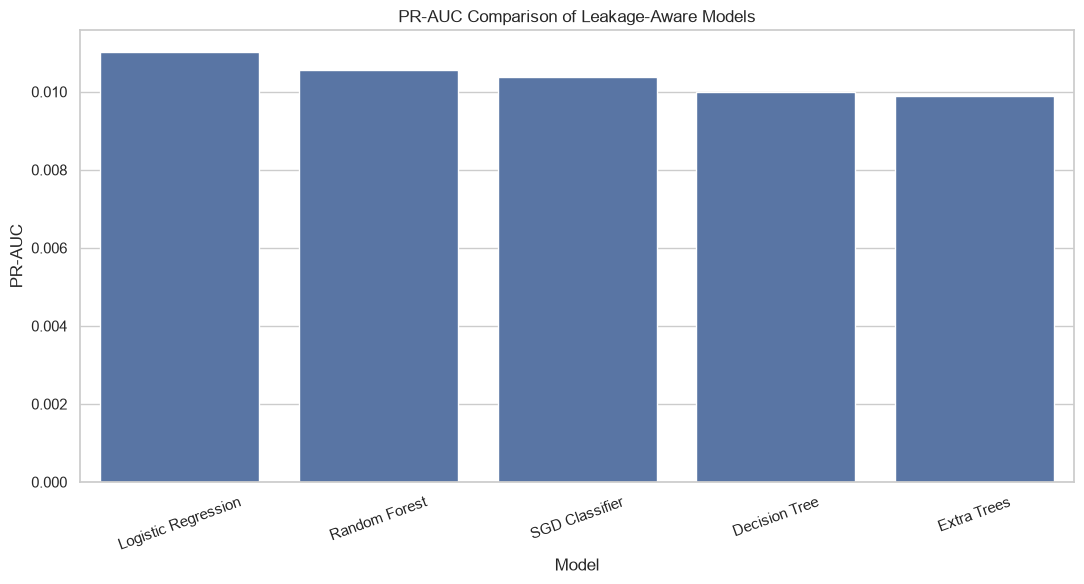


Selected model: Logistic Regression

Optimized threshold: 0.569
Validation F1: 0.0284


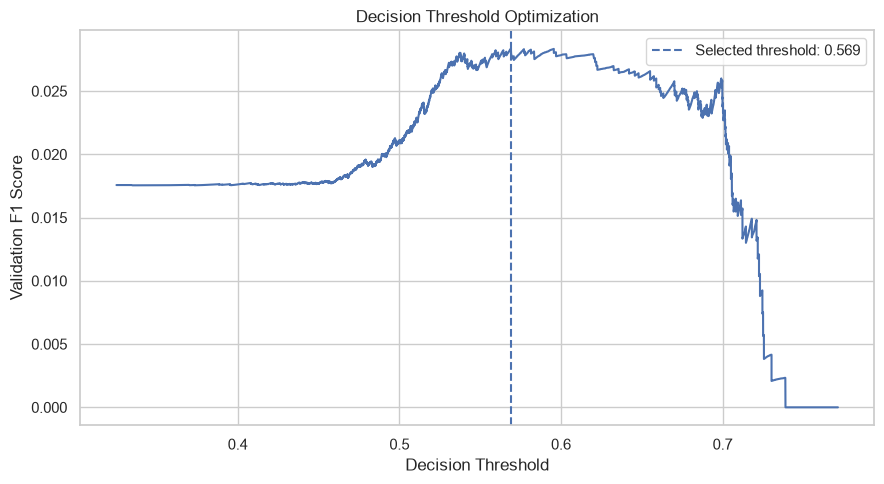


========== FINAL TEST CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

  Legitimate       0.99      0.93      0.96    109025
       Fraud       0.02      0.13      0.03       975

    accuracy                           0.92    110000
   macro avg       0.50      0.53      0.50    110000
weighted avg       0.98      0.92      0.95    110000


FINAL TEST METRICS


,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.569,0.9246,0.0166,0.1292,0.0295,0.5402,0.0117


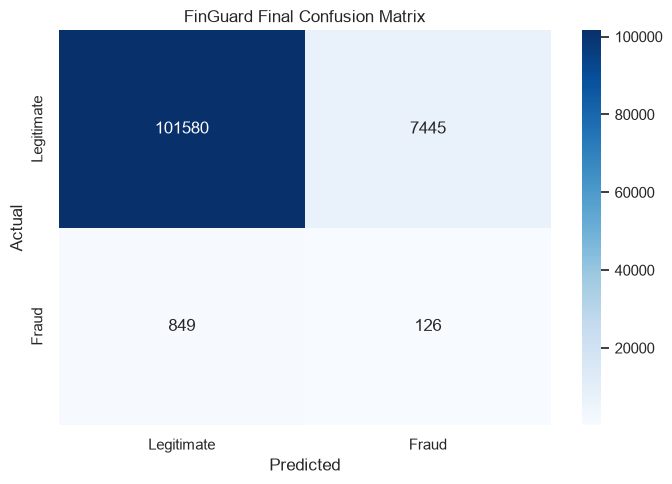

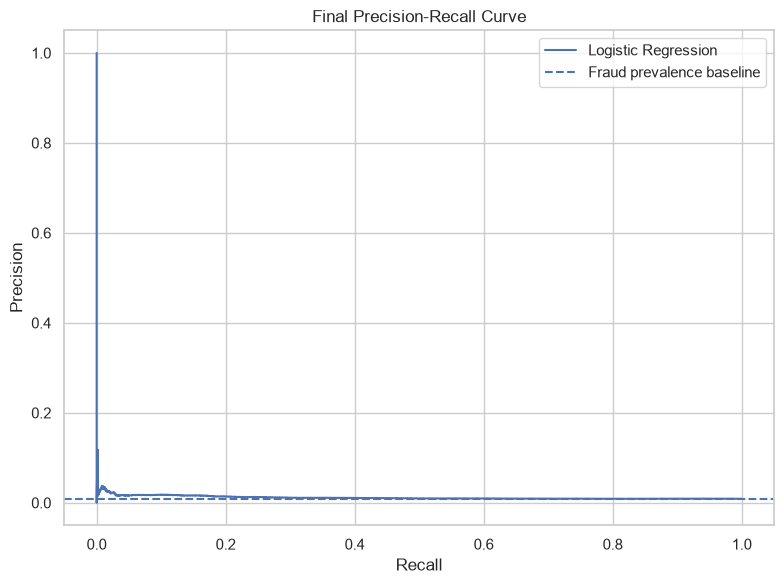

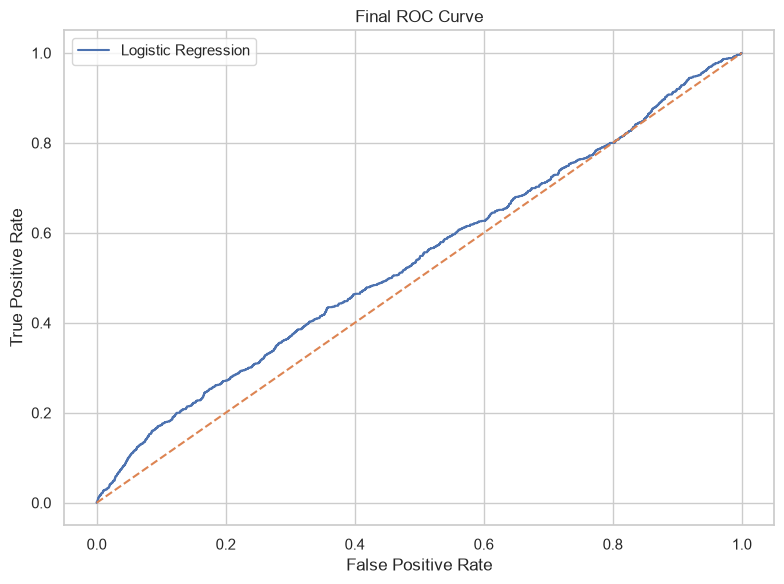

Native feature importance unavailable for the selected model.

FINGUARD CORRECTED ML EXPERIMENT COMPLETED
Selected model: Logistic Regression
Decision threshold: 0.569
Test accuracy: 0.9246
Test precision: 0.0166
Test recall: 0.1292
Test F1: 0.0295
Test ROC-AUC: 0.5402
Test PR-AUC: 0.0117

Model saved in: c:\Users\Sarthak\OneDrive\Desktop\FINTECH\outputs
Charts saved in: c:\Users\Sarthak\OneDrive\Desktop\FINTECH\visualizations

All corrected experiments completed!


In [61]:

# ============================================================
# FINGUARD: CORRECTED LEAKAGE-AWARE ML EXPERIMENT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import time

from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)

sns.set_theme(style="whitegrid")


# ============================================================
# 1. PROJECT PATHS
# ============================================================

current = Path.cwd()

while current != current.parent:
    if (current / "data").is_dir():
        PROJECT_ROOT = current
        break
    current = current.parent
else:
    raise FileNotFoundError("FINTECH project folder not found.")

OUTPUT_DIR = PROJECT_ROOT / "outputs"
VIZ_DIR = PROJECT_ROOT / "visualizations"

OUTPUT_DIR.mkdir(exist_ok=True)
VIZ_DIR.mkdir(exist_ok=True)

print("Project:", PROJECT_ROOT)


# ============================================================
# 2. TARGET LEAKAGE AUDIT
# ============================================================

data = df_ml.copy()

# Recreate suspected synthetic fraud rule
suspected_rule = (
    (
        (data["transaction_hour"] >= 22) |
        (data["transaction_hour"] < 6)
    )
    &
    (data["transaction_amount"] > 500000)
)

print("\n========== TARGET LEAKAGE AUDIT ==========")

print(
    pd.crosstab(
        suspected_rule,
        data["is_fraud"],
        normalize="index"
    ).round(4)
)

print("\nFraud rate by suspected rule (%):")

print(
    data.groupby(suspected_rule)["is_fraud"]
    .mean()
    .mul(100)
    .round(2)
)


# ============================================================
# 3. CORRECT FEATURE SELECTION
# ============================================================

target = "is_fraud"

# Features directly related to suspected fraud rule
suspicious_features = [
    "transaction_hour",
    "transaction_amount",
    "is_night",
    "amount_log",
    "amount_balance_ratio"
]

# Identifier and raw date/time columns
identifier_columns = [
    "transaction_id",
    "customer_id",
    "account_id",
    "transaction_date",
    "transaction_time",
    "suspected_rule"
]

# Ensure target is valid
data = data.dropna(subset=[target]).copy()

data = data[
    data[target].isin([0, 1])
].copy()

# Remove target and unwanted predictors
drop_columns = [
    target
] + identifier_columns + suspicious_features

X_safe = data.drop(
    columns=drop_columns,
    errors="ignore"
).copy()

y_safe = data[target].astype(int)

# Remove any raw datetime columns that remain
datetime_columns = X_safe.select_dtypes(
    include=["datetime", "datetimetz"]
).columns.tolist()

X_safe = X_safe.drop(
    columns=datetime_columns,
    errors="ignore"
)

# Remove constant columns
constant_columns = [
    col for col in X_safe.columns
    if X_safe[col].nunique(dropna=False) <= 1
]

X_safe = X_safe.drop(
    columns=constant_columns
)

print("\n========== FEATURE SELECTION ==========")

print("Suspicious features present in original data:")
print([c for c in suspicious_features if c in data.columns])

print("\nSuspicious features remaining:")
print([c for c in suspicious_features if c in X_safe.columns])

print("\nIdentifier columns remaining:")
print([c for c in identifier_columns if c in X_safe.columns])

print("\nFinal feature count:", X_safe.shape[1])
print("Target records:", len(y_safe))

print("\nSelected features:")
print(X_safe.columns.tolist())

assert not any(
    c in X_safe.columns
    for c in suspicious_features
), "Suspicious feature still present!"

assert "is_fraud" not in X_safe.columns

print("\nFeature selection verified successfully!")


# ============================================================
# 4. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# First: 80% development, 20% final test
X_dev, X_test, y_dev, y_test = train_test_split(
    X_safe,
    y_safe,
    test_size=0.20,
    random_state=42,
    stratify=y_safe
)

# Second: 80% training, 20% validation of development data
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    random_state=42,
    stratify=y_dev
)

print("\n========== DATA SPLIT ==========")

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

print("\nTraining fraud rate:", round(y_train.mean() * 100, 3), "%")
print("Validation fraud rate:", round(y_val.mean() * 100, 3), "%")
print("Testing fraud rate:", round(y_test.mean() * 100, 3), "%")


# ============================================================
# 5. PREPROCESSING PIPELINE
# ============================================================

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nNumerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


# ============================================================
# 6. DEFINE FIVE MACHINE LEARNING MODELS
# ============================================================

safe_models_definition = {

    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=20,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=16,
        min_samples_leaf=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        max_depth=16,
        min_samples_leaf=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "SGD Classifier": SGDClassifier(
        loss="log_loss",
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
}


# ============================================================
# 7. TRAIN FIVE MODELS AND VALIDATE
# ============================================================

trained_safe_models = {}
safe_results = []

for name, model in safe_models_definition.items():

    start_time = time.time()

    print(f"\nTraining {name}...")

    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(model))
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_val)

    probabilities = pipeline.predict_proba(X_val)[:, 1]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        ),
        "PR-AUC": average_precision_score(
            y_val, probabilities
        ),
        "Training Time (seconds)": round(
            time.time() - start_time, 2
        )
    }

    safe_results.append(metrics)

    trained_safe_models[name] = pipeline

    print("Completed:", name)


# ============================================================
# 8. COMPARE MODEL PERFORMANCE
# ============================================================

safe_results_df = pd.DataFrame(safe_results)

safe_results_df = safe_results_df.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

print("\n========== MODEL COMPARISON ==========")

display(safe_results_df.round(4))

safe_results_df.to_csv(
    OUTPUT_DIR / "leakage_aware_model_comparison.csv",
    index=False
)


# ============================================================
# 9. VISUALIZE MODEL COMPARISON
# ============================================================

plt.figure(figsize=(11, 6))

sns.barplot(
    data=safe_results_df,
    x="Model",
    y="PR-AUC"
)

plt.title("PR-AUC Comparison of Leakage-Aware Models")
plt.ylabel("PR-AUC")
plt.xlabel("Model")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    VIZ_DIR / "leakage_aware_comparison.png",
    dpi=300
)

plt.show()


# ============================================================
# 10. SELECT BEST MODEL USING VALIDATION PR-AUC
# ============================================================

best_model_name = safe_results_df.iloc[0]["Model"]

best_model = trained_safe_models[best_model_name]

print("\nSelected model:", best_model_name)


# ============================================================
# 11. DECISION THRESHOLD OPTIMIZATION
# ============================================================

# Threshold is selected using validation data only.
# Final test data remains untouched.

validation_probabilities = (
    best_model.predict_proba(X_val)[:, 1]
)

precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_val,
        validation_probabilities
    )
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    /
    (
        precision_values[:-1] +
        recall_values[:-1] + 1e-10
    )
)

best_threshold_index = np.argmax(f1_values)

best_threshold = float(
    thresholds[best_threshold_index]
)

print("\nOptimized threshold:", round(best_threshold, 4))
print("Validation F1:", round(
    f1_values[best_threshold_index], 4
))

plt.figure(figsize=(9, 5))

plt.plot(thresholds, f1_values)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected threshold: {best_threshold:.3f}"
)

plt.title("Decision Threshold Optimization")
plt.xlabel("Decision Threshold")
plt.ylabel("Validation F1 Score")
plt.legend()
plt.tight_layout()

plt.savefig(
    VIZ_DIR / "threshold_optimization.png",
    dpi=300
)

plt.show()


# ============================================================
# 12. FINAL TEST EVALUATION
# ============================================================

test_probabilities = (
    best_model.predict_proba(X_test)[:, 1]
)

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("\n========== FINAL TEST CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

final_metrics = {
    "Model": best_model_name,
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, test_probabilities
    ),
    "PR-AUC": average_precision_score(
        y_test, test_probabilities
    )
}

final_metrics_df = pd.DataFrame([final_metrics])

print("\nFINAL TEST METRICS")

display(final_metrics_df.round(4))


# ============================================================
# 13. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    test_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("FinGuard Final Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    VIZ_DIR / "final_confusion_matrix.png",
    dpi=300
)

plt.show()


# ============================================================
# 14. PRECISION-RECALL CURVE
# ============================================================

precision_curve, recall_curve, _ = precision_recall_curve(
    y_test,
    test_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"{best_model_name}"
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    label="Fraud prevalence baseline"
)

plt.title("Final Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()

plt.savefig(
    VIZ_DIR / "final_precision_recall_curve.png",
    dpi=300
)

plt.show()


# ============================================================
# 15. ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(
    y_test,
    test_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"{best_model_name}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("Final ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()

plt.savefig(
    VIZ_DIR / "final_roc_curve.png",
    dpi=300
)

plt.show()


# ============================================================
# 16. FEATURE IMPORTANCE
# ============================================================

classifier = best_model.named_steps["classifier"]

if hasattr(classifier, "feature_importances_"):

    feature_names = (
        best_model
        .named_steps["preprocessor"]
        .get_feature_names_out()
    )

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": classifier.feature_importances_
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    ).head(15)

    print("\nTOP 15 FEATURES")

    display(importance_df)

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Important Features")
    plt.tight_layout()

    plt.savefig(
        VIZ_DIR / "feature_importance.png",
        dpi=300
    )

    plt.show()

    importance_df.to_csv(
        OUTPUT_DIR / "feature_importance.csv",
        index=False
    )

else:
    print(
        "Native feature importance unavailable "
        "for the selected model."
    )


# ============================================================
# 17. SAVE FINAL MODEL AND EXPERIMENT RESULTS
# ============================================================

joblib.dump(
    best_model,
    OUTPUT_DIR / "final_fraud_model.pkl"
)

safe_results_df.to_csv(
    OUTPUT_DIR / "leakage_aware_model_comparison.csv",
    index=False
)

final_metrics_df.to_csv(
    OUTPUT_DIR / "final_model_metrics.csv",
    index=False
)

with open(
    OUTPUT_DIR / "decision_threshold.json",
    "w"
) as f:

    json.dump(
        {"threshold": best_threshold},
        f,
        indent=4
    )


# Save experiment metadata

experiment_summary = {
    "project": "FinGuard - Banking Fraud Detection",
    "selected_model": best_model_name,
    "decision_threshold": best_threshold,
    "training_records": int(len(X_train)),
    "validation_records": int(len(X_val)),
    "test_records": int(len(X_test)),
    "features_used": X_safe.columns.tolist(),
    "suspicious_features_removed": [
        c for c in suspicious_features if c in data.columns
    ],
    "final_metrics": {
        key: (
            float(value)
            if isinstance(value, (np.integer, np.floating))
            else value
        )
        for key, value in final_metrics.items()
    }
}

with open(
    OUTPUT_DIR / "experiment_summary.json",
    "w"
) as f:

    json.dump(
        experiment_summary,
        f,
        indent=4
    )


# ============================================================
# 18. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 55)
print("FINGUARD CORRECTED ML EXPERIMENT COMPLETED")
print("=" * 55)

print("Selected model:", best_model_name)
print("Decision threshold:", round(best_threshold, 4))
print("Test accuracy:", round(final_metrics["Accuracy"], 4))
print("Test precision:", round(final_metrics["Precision"], 4))
print("Test recall:", round(final_metrics["Recall"], 4))
print("Test F1:", round(final_metrics["F1 Score"], 4))
print("Test ROC-AUC:", round(final_metrics["ROC-AUC"], 4))
print("Test PR-AUC:", round(final_metrics["PR-AUC"], 4))

print("\nModel saved in:", OUTPUT_DIR)
print("Charts saved in:", VIZ_DIR)

print("\nAll corrected experiments completed!")
